# **Travail 1 STT-2920 (5\%)**


*   Vous devez remplir ce notebook en suivant les directives (Ne modifier que les éléments aux endroits préciser). Pour modifier une cellule, il suffit de double-cliquer dessus. Pour exécuter une cellule, il suffit de faire shift+entrer.

*   Vous pouvez faire ce travail seul ou en équipe de deux.

*   Vous devez remettre le notebook .ipynb rempli (et que le tout compile correctement). Conseil, faites un test sur google colab avant la dernière remise. Remettre dans la boite de remise sur Mon Portail. Remettre une seule remise par équipe. Renommer le fichier Travail_1_STT-2920_NI1_NI1.ipynb où NI1 et NI2 sont les numéros d'identifications des deux coéquipiers.

* N'hésitez pas à consulter l'aide en ligne sur les foncitonnalités utilisés.  

* Notez que les librairies et fonctionnalités utilisées sont déjà importées à travers les cellules de code ci-dessous. Conséquemment, aucun import supplémentaire ne sera nécessaire.

* Notez que le notebook compile déjà à la base sans modification (bien entendu, les sorties ne sont pas bonnes pour l'instant, elles le seront lorsque vous aurez fait les modifications adéquates).

*Chaque question vaut 5 points. Le travail sera donc corrigé sur 15 points.

**À remplir vos prénoms, noms et NI**

Coéquipier 1: Prénom: Théo     Nom: Mailhot       NI: 537 291 728

Coéquipier 2: Prénom: Alexis   Nom: Gauthier      NI: 537 289 373


In [19]:
#Ne pas changer cette cellule
import numpy as np
from math import*
import matplotlib.pyplot as plt
import statistics

**Question 1**

Voici 3 dés à 3 faces. Chaque face a la même probabilités de survenir.

Dé A (dé numéro 1) : Les faces sont 1, 5 et 9.

Dé B (dé numéro 2) : Les faces sont 3, 4 et 8.

Dé C (dé numéro 3) : Les faces sont 2, 6 et 7.

Le joueur A choisit un dé, ensuite le joueur B doit choisir un des deux autres dés. Les deux joueurs s'affrontent ensuite en lançant leur dé respectif une fois. Le plus grand résultat gagne. Quelle est votre stratégie si vous êtes le joueur A ? Quelle est votre stratégie si vous êtes le joueur B ? Préférez-vous être le joueur A ou bien le joueur B ? Expliquez.



Expliquez ici votre intuition par rapport aux questions précédentes. Tentez d'y réponde et expliquez.

Si nous sommes le joeur A, il n'y a pas vraiment de stratégie qui garantie une probabilité plus élevé de victoire. La stratégie est donc de prendre un dé au hasard. Si nous sommes le joeur B, la stratégie est de choisir le dé qui est avantagé par rapport au dé qu'à choisi le joueur A. Nous préférons être le joueur B, car en dénombrant les scénarios de combat de dé, pour chaque combinaison (A vs B, B vs C, C vs A), un des deux dé gagne un plus grand nombre de scénario. Exemple, si le joueur A prend le dé A, il est préférable de prendre le dé C, car celui-ci gagne plus de scénario contre le A (5/9 pour le C et 4/9 pour le A) Il nous serait donc possible de choisir le dé qui avantage le plus (une fois connu).

**Pour valider votre intuition, nous allons faire une simulation.**

La cellule de code ci-dessous permet de définir la fonction qui simule chacun des dés.

La fonction de_1() simule le dé A,

la fonction de_2() simule le dé B,

la fonction de_3() simule le dé C.

Chacune des fonctions se base sur l'obtention d'abord d'un nombre réel aléatoire uniforme sur l'intervalle $[0,1]$ par la fonction np.random.rand(). vous ne devez utiliser aucune autre fonction tirant une variable aléatoire. Vous pouvez lire la section 4.10.1 des notes de cours, notamment l'exemple 21.


In [20]:
def de_1():
# Cette fonction renvoit le résultat d'un tirage du dé no 1.
# la sortie resultat doit être un des trois nombres possibles du dé avec équiprobabilité.
  x=np.random.rand() # x contient maitenant un nombre aléatoire sur l'intervalle [0,1]
  x=3*x #Valeur inclus entre 0 et 3 (Équiprobabilités simples)
  resultat=0

  while x == 3:
    x=np.random.rand()

  if int(x) == 0:
    resultat = 1

  if int(x) == 1:
    resultat = 5

  if int(x) == 2:
    resultat = 9

  return resultat

def de_2():
# Cette fonction renvoit le résultat d'un tirage du dé no 2.
# la sortie resultat doit être un des trois nombres possibles du dé avec équiprobabilité.
  x=np.random.rand() # x contient maitenant un nombre aléatoire sur l'intervalle [0,1]
  x=3*x #Valeur inclus entre 0 et 3 (Équiprobabilités simples)
  resultat=0
  
  while x == 3:
    x=np.random.rand()
  
  if int(x) == 0:
    resultat = 3
  
  if int(x) == 1:
    resultat = 4
  
  if int(x) == 2:
    resultat = 8
  
  return resultat

def de_3():
# Cette fonction renvoit le résultat d'un tirage du dé no 3.
# la sortie resultat doit être un des trois nombres possibles du dé avec équiprobabilité.
  x=np.random.rand() # x contient maitenant un nombre aléatoire sur l'intervalle [0,1]
  x=3*x #Valeur inclus entre 0 et 3 (Équiprobabilités simples)
  resultat=0
  
  while x == 3:
    x=np.random.rand()
  
  if int(x) == 0:
    resultat = 2
  
  if int(x) == 1:
    resultat = 6
  
  if int(x) == 2:
    resultat = 7
  
  return resultat


On test maintenant nos fonctions de_1(), de_2() et de_3() à l'aide de 1000 simulations pour voir s'ils se comportent de la bonne façon.

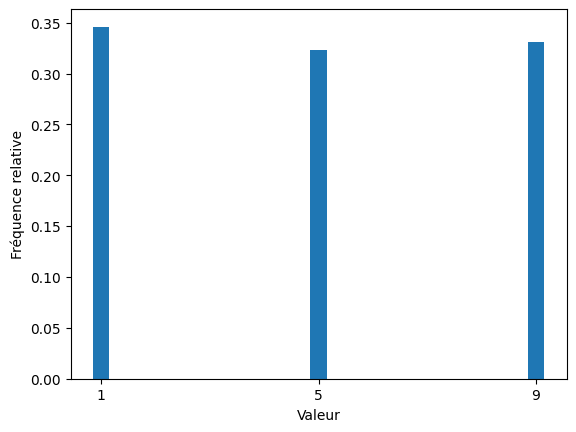

In [21]:
#Rien à faire dans cette cellule

#test du dé no A.
n=1000
xA=np.zeros(n)
for i in range(n):
  xA[i]=de_1()

#la ligne qui suit permet de stocker les valeurs qui composes le vecteur xA et donne la fréquence associé à chaque valeur.
valeurs, frequences = np.unique(xA, return_counts=True)
frequences=frequences/n

#Graphique du diagramme en bâton.
plt.bar(valeurs, frequences, width=0.3)
plt.xticks(valeurs)
plt.xlabel('Valeur')
plt.ylabel('Fréquence relative')
plt.show()

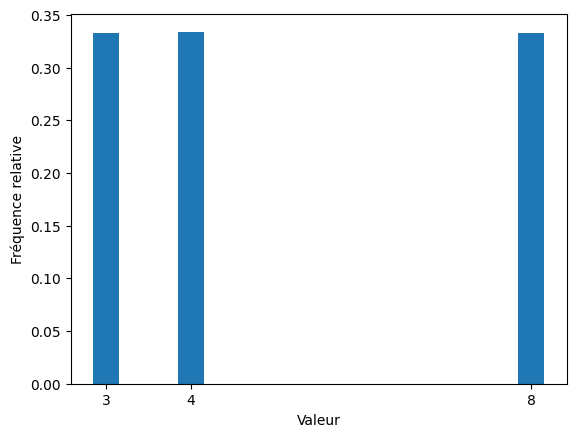

In [22]:
#test du dé no B.
n=1000
xB=np.zeros(n)
for i in range(n):
  xB[i]=de_2()

#la ligne qui suit permet de stocker les valeurs qui composes le vecteur xB et donne la fréquence associé à chaque valeur.
valeurs, frequences = np.unique(xB, return_counts=True)
frequences=frequences/n

#Graphique du diagramme en bâton.
plt.bar(valeurs, frequences, width=0.3)
plt.xticks(valeurs)
plt.xlabel('Valeur')
plt.ylabel('Fréquence relative')
plt.show()

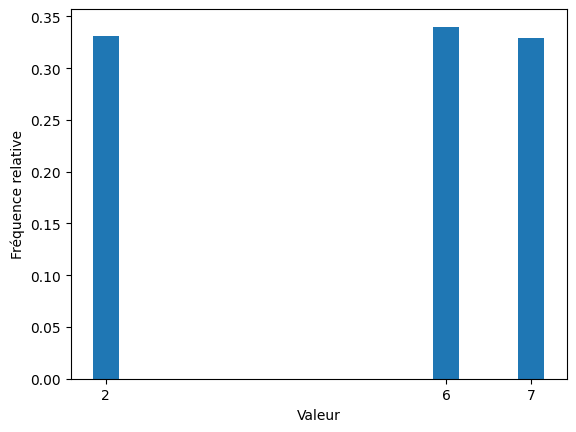

In [23]:
#test du dé no C.
n=1000
xC=np.zeros(n)
for i in range(n):
  xC[i]=de_3()

#la ligne qui suit permet de stocker les valeurs qui composes le vecteur xC et donne la fréquence associé à chaque valeur.
valeurs, frequences = np.unique(xC, return_counts=True)
frequences=frequences/n

#Graphique du diagramme en bâton.
plt.bar(valeurs, frequences, width=0.3)
plt.xticks(valeurs)
plt.xlabel('Valeur')
plt.ylabel('Fréquence relative')
plt.show()

Est-ce que les graphiques qui précèdent sont ce qui est attendu ?

Oui, les graphiques de répartition de probabilité illustrent une répartion qui tend vers 1/3 pour chaque valeurs possibles.
Avec un plus grand nombre d'ittérations, le probabilités vont tendre de plus en plus vers 1/3.

Les fonctions suivantes servent à programmer $n$ affrontement de deux dés.

La fonction AvsB pour le dé A contre le dé B.

La fonction BvsC pour le dé B contre le dé C.

La fonction AvcC pour le dé C contre le dé A.

In [24]:
def AvsB(n):
#Simule n affrontement entre le dé A et le dé B
#Reçoit un nombre naturel en entrée.
#Renvoie  en sortie un vecteur (de type np.array) dont
#l'entrée no i donne le résultat de l'affrontement no i+1 (rappel: l'indiçage débute à 0 en Python).
#on stockera la valeur 1 si le dé A gagne l'affrontement en question et 2 si c'est le dé B qui gagne.
#Le vecteur en sortie est nommé resultats.
  resultats=np.zeros(n,int) #Tableau à remplir
  for i in range(n):
    #tirer une valeur du dé A et une valeur du dé B à l'aide des fonctions précédentes
    res_A=de_1() #Résultat du dé A
    res_B=de_2() #Résultat du dé B
    if res_A>res_B:
      resultats[i]=1 #Si A>B on indique 1
    else:
      resultats[i]=2 #Si B>A on indique 2

  return resultats

def BvsC(n):
#Simule n affrontement entre le dé B et le dé C
#Reçoit un nombre naturel en entrée.
#Renvoie  en sortie un vecteur (de type np.array) dont
#l'entrée no i donne le résultat de l'affrontement no i+1 (rappel: l'indiçage débute à 0 en Python).
#on stockera la valeur 2 si le dé B gagne l'affrontement en question et 3 si c'est le dé C qui gagne.
#Le vecteur en sortie est nommé resultats.
  resultats=np.zeros(n,int)
  for i in range(n):
    #tirer une valeur du dé B et une valeur du dé C à l'aide des fonctions précédentes
    res_B=de_2() #Résultat du dé B
    res_C=de_3() #Résultat du dé C
    if res_B>res_C:
      resultats[i]=2 #Si B>C on indique 2
    else:
      resultats[i]=3 #Si C>B on indique 3

  return resultats

def AvsC(n):
#Simule n affrontement entre le dé A et le dé C
#Reçoit un nombre naturel en entrée.
#Renvoie  en sortie un vecteur (de type np.array) dont
#l'entrée no i donne le résultat de l'affrontement no i+1 (rappel: l'indiçage débute à 0 en Python).
#on stockera la valeur 1 si le dé A gagne l'affrontement en question et 3 si c'est le dé C qui gagne.
#Le vecteur en sortie est nommé resultats.
  resultats=np.zeros(n,int)
  for i in range(n):
    #tirer une valeur du dé A et une valeur du dé C à l'aide des fonctions précédentes
    res_A=de_1() #Résultat de A
    res_C=de_3() #Résultat de C   
    if res_A>res_C:
      resultats[i]=1 #Si A>C on indique 1
    else:
      resultats[i]=3 #Si C>A on indique 3

  return resultats

La cellule suivant utilise les fonctions programmées précédemment pour simulé n affrontements entre les 3 combinaisons de dé.

In [25]:
n=1000
resultats_AvsB=AvsB(n)
resultats_BvsC=BvsC(n)
resultats_AvsC=AvsC(n)

La cellule suivante calcul la proportion de combats que le dé A a gagné contre le dé B.
La cellule suivante calcul la proportion de combats que le dé B a gagné contre le dé C
La cellule suivante calcul la proportion de combats que le dé C a gagné contre le dé A


In [26]:
n_A=np.sum(resultats_AvsB == 1)
p_A=n_A/n

n_B=np.sum(resultats_BvsC == 2)
p_B=n_B/n

n_C=np.sum(resultats_AvsC == 3)
p_C=n_C/n

print(f"Le dé A a gagné {p_A * 100:.2f}% des combats contre le dé B")
print(f"Le dé B a gagné {p_B * 100:.2f}% des combats contre le dé C")
print(f"Le dé C a gagné {p_C * 100:.2f}% des combats contre le dé A")

Le dé A a gagné 57.90% des combats contre le dé B
Le dé B a gagné 53.90% des combats contre le dé C
Le dé C a gagné 55.10% des combats contre le dé A


Commentez les résultat. Est-ce que c'est conforme à ce que vous vous attendiez ? Expliquez brièvement.

Oui, c'est ce à quoi nous nous attendions. En fait, chaque dé est avantagé par rapport à un autre. Nous nous attendions à environ 55.55% de victoire pour le dé gagant dans ces scénarios. Donc, le dé A est avantagé par rapport au dé B, le dé B est avantagé par rapport au dé C et le dé C est avantagé par rapport au dé A.

**Question no 2**

Le but de cette question est d'illustrer comment on peut générer une variable aléatoire ayant n'importe quelle densité à partir d'un générateur donnant un nombre réel tiré uniformément sur l'intervalle $[0,1].$

Supposons que l'on a une variable $U\sim\mathcal{U}([0,1]).$

Supposons que l'on souhaite définir, à partir de $U,$ une variable aléatoire $X$ qui aura la densité $f(x)$ connue (et comme fonction de répartition $F(x)$ connue). Autrement dit, on cherche une transformation $g$ telle que $X=g(U)$ et telle que la variable aléatoire $X$ aura la fonction de répartition $F(x).$
On s'aperçoit que la transformation que si on prend $g$ comme la fonction inverse de la fonction de répartition: $g\equiv F^{-1},$ cela fonctionnera.
Effectivement, si on définit $X=F^{-1}(U),$ on aura que la fonction de répartition de $X$ sera
\begin{eqnarray*}
\mathbb{P}[X\leq x]&=& \mathbb{P}[F^{-1}(U)\leq x]\\
&=& \mathbb{P}[U\leq F(x)]\tag{en isolant $U$ et utilisant que $F$ est croissante}\\
&=& \dfrac{F(x)-0}{1-0}\tag{car $U$ est uniforme sur $[0,1]$}\\
&=& F(x)
\end{eqnarray*}
On peut donc simuler une variable aléatoire $X$ de fonction de répartition désirée $F(x)$ à partir de la simulation d'une variable $U\sim\mathcal{U}([0,1]),$ il suffit de calculer $X=F^{-1}(U).$

Le fait mathématique qui précède est aussi bien expliquée dans la section 4.10.3 des notes de cours.

On désire construire une fonction maison en Python qui simulera une variable aléatoire exponentielle de paramètre $\lambda.$
On rappelle que si $X\sim\mathcal{E}(\lambda),$ on a que
$f_X(x)=\begin{cases}
    \lambda\mathrm{e}^{-\lambda x} & \text{si } x > 0, \\
    0 & \text{sinon }.
\end{cases}
$

Obtenez la fonction de répartition de $F(x)$ de $X.$

Faites la démarche complète dans cette cellule-ci, en utilisant la symbolique mathématique appropriée.

**À faire...**

Obtener la fonction inverse de $F,$ nommé $F^{-1}.$ Vous devez faire la démarche mathématique vous permettant d'obtenir l'expression de $F^{-1}(u)$ pour $u\in[0,1].$

**À faire...**

Valider à l'aide d'un calcul mathématique votre fonction inverse. On doit avoir que $F^{-1}(F(u))=u.$

**À faire**

Dans la cellule ci-dessous, programmer la fonction de répartition inverse trouver précédemment.

In [27]:
#N'utilisez que les fonctionnalités de base (fonctions mathématiques de base,
#par exemple, np.sin(), np.exp(), np.log(), etc...ainsi que les opérations arithmétiques
# de base) de la librairie numpy.

#Cette fonction reçoit un nombre u (ou un vecteur de nombres u) en entrée
#Ainsi qu'un nombre lambda_ plus grand que 0.
#retourne en sortie un vecteur dont chaque élément est la valeur de la fonction
#de répartition inverse de la loi exponentielle de l'élément en entrée.
def F_inverse_exp(u,lambda_):
  x = []
  for i in range(len(u)):
    Finvu =-np.log(1-u[i])/lambda_
    x.append(Finvu)
  return(x)


La fonction ci-dessous utilise la fonction que vous venez de définir pour générer aléatoirement $n$ nombres selon la loi exponentielle de paramètre lambda_ à partir de la simulation de $n$ nombres aléatoires tirés uniformément sur l'intervalle $[0,1].$

In [28]:
#Cette fonction reçoit lambda_ un nombre réel positif et n un entier positif
#Cette fonction retourne un vecteur (np.array) dont chaque nombre provient d'une
#loi exponentielle de paramètre lambda_
def rand_exp(lambda_,n):
  u=np.random.rand(n)
  #u contient n nombres réels tirés de la loi uniforme sur l'intervalle [0,1].
  #À modifier
  x=F_inverse_exp(u,lambda_)
  return(x)

On teste maintenant notre générateur maison.
On fait maintenant $m$ tirages de la variable aléatoire $X$ de loi exponentielle de paramètre $\lambda=3$ à l'aide de notre générateur maison.
On trace l'histogramme des valeurs de $X$ obtenues.

In [ ]:
m=10000 #Laisser comme tel

#Remplir la ligne ci-dessous.
lambda_ = 3
x=rand_exp(1/lambda_,m)

print(x)

[np.float64(0.2505557371414867), np.float64(4.8862986980571135), np.float64(9.706207633683155), np.float64(1.447062902008154), np.float64(1.119799313558632), np.float64(5.102348960162587), np.float64(1.909957710289793), np.float64(9.664364521388064), np.float64(0.8526193607236625), np.float64(1.1942230160855165), np.float64(7.493340389035032), np.float64(0.41101566307761406), np.float64(0.7017799269241228), np.float64(5.1184828166849865), np.float64(0.37947786937940153), np.float64(0.1901676726484108), np.float64(2.193570866014808), np.float64(4.568277694709555), np.float64(0.20824576514166318), np.float64(1.374774990798223), np.float64(3.678412431780883), np.float64(0.5570195957831262), np.float64(0.18062022235802505), np.float64(0.4967895760237062), np.float64(3.4643479837959035), np.float64(2.040844514251962), np.float64(4.195906494479762), np.float64(9.49634718633594), np.float64(2.4752505117955184), np.float64(1.1033648314527278), np.float64(8.880588678102187), np.float64(0.365136

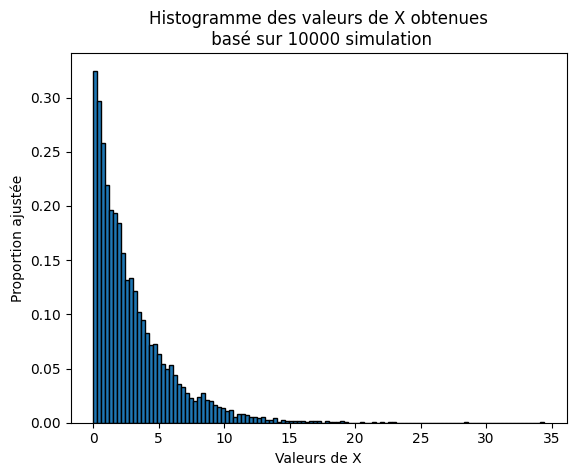

In [37]:
#Ne pas modifier cette cellule
#Représentation graphique sous forme d'histogramme des $m$ valeurs obtenues de
#la variable $X.$
plt.hist(x,bins='auto', density=True,edgecolor="black")
#L'option density permet de s'assurer que la hauteur des rectangles soient ajustées
#pour que l'aire sous l'histogramme donne 1.
plt.xlabel('Valeurs de X')
plt.ylabel('Proportion ajustée')
plt.title("Histogramme des valeurs de X obtenues\n basé sur {} simulation".format(m))
plt.show()


Commentez la forme de l'histogramme. Est-ce que cela est conforme à ce qui est attendu ? Expliquez.

La fonction décrite par la fonction inverse de u représente effectivement une fonction exponentielle négative de lambda 3.

On va maintenant comparer avec la fonction np.random.exponentiel() qui permet d'obtenir des nombres aléatoires provenant d'une loi exponentielle.

In [38]:
#Utilisez la fonction np.random.exponential() avec les bonnes options pour obtenir
#m nombres aléatoires tirées selon la loi exponentielle de paramètre lambda. On prend
#le même lambda que plus haut. Attention de bien lire la documentation sur les options
#à passer à cette fonction.

y=np.random.exponential(1/lambda_,m) #Ok
print(y)

[0.33085796 0.23054771 0.25468283 ... 1.26790601 0.1514139  0.30184432]


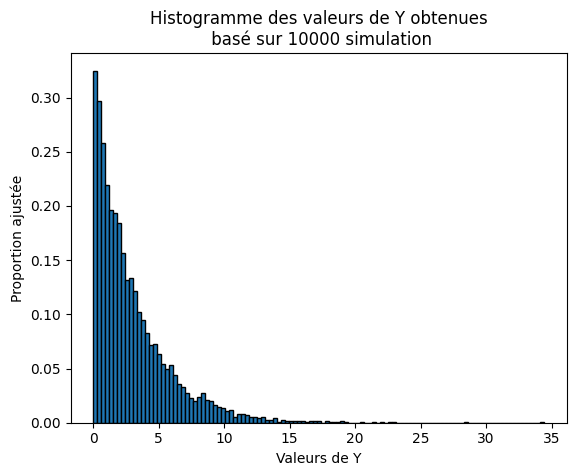

In [39]:
#Histogramme des valeurs de $y.$
plt.hist(x,bins='auto', density=True,edgecolor="black")
plt.xlabel('Valeurs de Y')
plt.ylabel('Proportion ajustée')
plt.title("Histogramme des valeurs de Y obtenues\n basé sur {} simulation".format(m))
plt.show()


Commentez les résultats. Est-ce que la forme de la distribution est conforme à l'histogramme produit avec votre fonction maison?

Oui, la fonction exponentielle de numpy est conforme a l'histogramme produit par notre fonction maison. Les formes générales des deux fonctions sont les mêmes.

**Question no 3**

Les 10 composantes fonctionnent en parallèle. Le système défaille lorsque toutes les composantes sont mortes. Le temps de vie (en heure) de la composante $i$ est modélisée par la variable aléatoire $X_i.$ On a que les $X_i$ sont i.i.d. (indépendantes et identiquement distribuées) selon la loi exponentielle de paramètre $\lambda=0.4.$ On a donc que $X_i\sim\mathcal{E}(0.4)$ pour $i=1,2,3,\ldots,10.$

Lorsqu'une première composante tombe en panne, le système continue de fonctionner, mais sa marge de tolérance diminue. On s'intéresse à l'étendue temporelle entre la toute première panne et la dernière panne entraînant l'arrêt total du sous-système, c'est-à-dire la variable aléatoire $T = \max(X_1,X_2,\ldots,X_n)-\min(X_1,X_2,\ldots,X_n)$. Cette durée représente la fenêtre critique d'intervention pour l'équipe d'exploitation.

On s'intéresse ici à estimer, à l'aide de simulation, la probabilité $\mathbb{P}[T\leq 5­]$

**Tâche demandée**

Générez un échantillon de $N = 100\,000$ simulations. Pour chaque simulation, simulez les temps de vie de $n = 10$ composantes indépendantes. Calculez la variable $T$ et vérifier si l'événement $T\leq 5$ se produit. Faites le cumul des cas favorables pour estimer ensuite la probabilité que l'événement survienne.

In [40]:
#La fonction ci-dessous réalise la simulation décrite dans l'énoncé
#lam représente le paramètre lambda (par défaut 0.4)
#T_seuil représente le temps maximale à ne pas dépasser (par défaut 5)
#n représente le nombre de composante (par défaut 10)
#N_sim représente le nombre simulation (par défaut 100000)
#La fonction retourne la probabilité estimée par fréquence relative.
def simulation(lam=0.4, T_seuil=5,n=10,N_sim=100000):

  #compteur pour le nombre d'expérience favorable à l'événement T inférieur ou égal à 5
  compteur_favorables = 0

  #Début de la boucle for faisant la simulation
  for k in range(N_sim):
    # Génération des 10 temps de vie pour un système
    X= np.random.exponential(1/lam,n) #Utilisez la fonction np.random.exponential()

    # Extraction de la plus petite et plus grande valeur des $X_i.$
    X_min = np.min(X) #Max
    X_max = np.max(X) #Min

    T = X_max - X_min
    # Vérification de la condition T <= T_seuil
    # Et incrémentation de compteur_favorables si oui.
    if T<=T_seuil:
      compteur_favorables +=1 #À modifier

  #Fin de la boucle for

  # Calcul de la probabilité empirique
  prob_estimee = compteur_favorables / N_sim

  return(prob_estimee)

In [41]:
# Paramètres de la simulation
lam = 0.4        # Paramètre de la loi exponentielle (taux de panne)
T_seuil = 5.0    # Seuil critique de temps (en heures)
n = 10           # Nombre de composantes en parallèle
N_sim = 100000   # Nombre de répétitions dans la simulation

prob_est=simulation()
print(f"Probabilité estimée avec {N_sim} simulation: {prob_est}")

Probabilité estimée avec 100000 simulation: 0.26984


Pour voir si cette estimation semble être d'une bonne précision, observons la convergence de la probabilité estimée lorsque le nombre de simulation augmente.
(Voir ci-dessous).

In [35]:
#Rien à changer dans cette cellule.
for N_sim in [100,1000,10000,100000,1000000]:
  prob_est=simulation(N_sim=N_sim)
  print(f"Probabilité estimée avec {N_sim} simulation: {prob_est}")

Probabilité estimée avec 100 simulation: 0.31
Probabilité estimée avec 1000 simulation: 0.274
Probabilité estimée avec 10000 simulation: 0.2661
Probabilité estimée avec 100000 simulation: 0.26901
Probabilité estimée avec 1000000 simulation: 0.270645


Commentez brièvement les résultats.

Les résultats des simulations s'approchent de plus en plus de la valeur réelle de probabilité pour un temps de vie du système T<=5 de P=0,27017 avec l'augmentation du nombre de simulation. 